# PhotoRing Simulator → exorings + geotrans
## Transit contact times (exorings) and numerical light curve (geotrans)

**Purpose:** Reference notebook for computing ringed-planet transit observables
with two complementary codes from the [PRisma pipeline](https://github.com/seap-udea/PRisma):

| Code | Role | Method |
|------|------|--------|
| **exorings** (Zuluaga et al. 2015) | Ingress/egress contact times, depth, photo-ring ratio | Analytical (closed-form) |
| **geotrans** | Numerical flux as function of time | Geometric overlap (Seager & Mallén-Ornelas 2003) |

**References:**
- Zuluaga, J.I., Kipping, D., Sucerquia, M., Alvarado, J.A., *ApJL* 803, L14 (2015). [arXiv:1502.00488](https://arxiv.org/abs/1502.00488)
- Seager, S. & Mallén-Ornelas, G., *ApJ* 585, 1038 (2003).
- Zuluaga, J.I., et al., *Astronomy & Computing* 40, 100623 (2022). [arXiv:2207.08636](https://arxiv.org/abs/2207.08636)


In [1]:
# ============================================================
# Download geotrans from the PRisma pipeline
# (Colab / any fresh environment: run once)
# ============================================================
import os, urllib.request, pathlib

GEOTRANS_URL_BASE = "https://raw.githubusercontent.com/seap-udea/PRisma/master/pipeline/geotrans"
GEOTRANS_FILES   = ["geotrans.py", "model.py", "__init__.py"]
GEOTRANS_DIR     = pathlib.Path("geotrans")
GEOTRANS_DIR.mkdir(exist_ok=True)

for fname in GEOTRANS_FILES:
    dest = GEOTRANS_DIR / fname
    if not dest.exists():
        url = f"{GEOTRANS_URL_BASE}/{fname}"
        print(f"Downloading {url}...")
        urllib.request.urlretrieve(url, dest)
    else:
        print(f"  {fname} already present.")

print("\ngeotrans ready.")



geotrans ready.


In [2]:
# ============================================================
# Download exorings from the PRisma pipeline
# (Colab / any fresh environment: run once)
# ============================================================
EXORINGS_URL_BASE = "https://raw.githubusercontent.com/seap-udea/PRisma/master/pipeline/exorings"
EXORINGS_FILES    = ["exorings.py", "basic.py", "forward.py", "__init__.py"]
EXORINGS_DIR      = pathlib.Path("exorings")
EXORINGS_DIR.mkdir(exist_ok=True)

for fname in EXORINGS_FILES:
    dest = EXORINGS_DIR / fname
    if not dest.exists():
        url = f"{EXORINGS_URL_BASE}/{fname}"
        print(f"Downloading {url}...")
        urllib.request.urlretrieve(url, dest)
    else:
        print(f"  {fname} already present.")

print("\nexorings ready.")


  exorings.py already present.
  basic.py already present.
  forward.py already present.
  __init__.py already present.

exorings ready.


In [3]:
# ============================================================
# Imports
# ============================================================
import sys, numpy as np
import matplotlib.pyplot as plt
from scipy.constants import G

# Add local path so both packages resolve correctly
sys.path.insert(0, ".")

# exorings – analytical contact-time / depth model
from exorings.basic  import ExoringsBasicParams, compute_exorings_basic
from exorings.forward import forward_observables

# geotrans – numerical flux model
import geotrans.geotrans as gt

# Convenience factors
deg = np.pi / 180   # degrees → radians
rad = 1.0 / deg     # radians → degrees
HOUR = 3600.0       # seconds per hour
DAY  = 86400.0      # seconds per day


/Users/jzuluaga/dev/seap-udea.github.io/apps/photoring-simulator/dev/geotrans/geotrans.py:3290: SyntaxWarning: invalid escape sequence '\O'
  """


## System parameters
The example below uses the **saturn-sun** preset (same as `model_code_pyppluss.ipynb`).
All sky-plane angles are defined as in the PhotoRing Simulator:

- `tilt` — sky-plane position angle of the ring semi-major axis (0° = horizontal)
- `ir`   — sky-plane inclination of the ring (0° = face-on, 90° = edge-on)
- `alpha = exp(-τ_normal)` — ring transparency (1 = fully transparent, 0 = opaque)


In [4]:
# ─────────────────────────────────────────────────────────────
# Primary system parameters  (sky-plane convention)
# ─────────────────────────────────────────────────────────────
p     = 0.084          # planet radius  [R*]
fi    = 1.58           # inner ring radius [Rp]
fe    = 2.35           # outer ring radius [Rp]
tilt  = 25.0           # sky-plane tilt [degrees]
ir    = 55.0           # sky-plane ring inclination [degrees]
b     = 0.25           # impact parameter [R*]
alpha = np.exp(-1)     # ring transmission = exp(-tau_normal); exp(-1) → tau=1
mstar = 1.0            # stellar mass   [M_sun]
rstar = 1.0            # stellar radius [R_sun]
porb  = 365.25         # orbital period [days]

# Stellar density in g/cm^3  (solar density ≈ 1.408 g/cm³)
rho_gcc = 1408.0 * mstar / rstar**3 / 1e3   # 1408 kg/m³ → g/cm³

# Ring opacity  tau = -ln(alpha)
tau = -np.log(alpha)

print(f"Stellar density  : {rho_gcc:.4f} g/cm³")
print(f"Ring tau_normal  : {tau:.4f}")
print(f"Ring alpha       : {alpha:.4f}")

# Scaled semi-major axis a/R*  from Kepler's third law
rho_SI = rho_gcc * 1e3                                    # kg/m³
a_Rs   = (G * rho_SI * (porb * DAY)**2 / (3*np.pi))**(1/3)
iorb   = np.arccos(min(1.0, b / a_Rs))
vorb   = 2*np.pi * a_Rs * np.sin(iorb) / (porb * DAY)   # orbital velocity [R*/s]

print(f"\na/R*             : {a_Rs:.4f}")
print(f"iorb             : {iorb*rad:.4f} deg")
print(f"vorb             : {vorb*3600:.6f} R*/hour")


Stellar density  : 1.4080 g/cm³
Ring tau_normal  : 1.0000
Ring alpha       : 0.3679

a/R*             : 214.9389
iorb             : 89.9334 deg
vorb             : 0.154061 R*/hour


## 1 · exorings — analytical contact times and transit depth

`compute_exorings_basic` returns all transit observables in one call.
The function uses the **improved support-function approach** (Numpaque et al. 2026)
to locate the four contact positions of the ring's shadow.


In [5]:
# ─────────────────────────────────────────────────────────────
# exorings – compute transit observables analytically
# ─────────────────────────────────────────────────────────────
params = ExoringsBasicParams(
    rhotrue = rho_gcc,
    P       = porb,
    b       = b,
    p       = p,
    fi      = fi,
    fe      = fe,
    tau     = tau,
    theta   = tilt,     # sky-plane tilt [degrees]
    ir      = ir,       # sky-plane inclination [degrees]
)

res = compute_exorings_basic(params)

print("──── exorings analytical results ────────────────────")
print(f"  a/R*                 : {res.a:.4f}")
print(f"  iorb                 : {res.iorb:.4f} deg")
print(f"  Transit depth  δ     : {res.delta:.6f}")
print(f"  Apparent radius pobs : {res.pobs:.6f}  R*")
print(f"  Blocking factor β    : {res.beta:.4f}")
print()
print(f"  T14  (total duration): {res.T14:.4f} hours")
print(f"  T23  (flat duration) : {res.T23:.4f} hours")
print(f"  T14p (planet only)   : {res.T14p:.4f} hours")
print(f"  T23p (planet only)   : {res.T23p:.4f} hours")
print()
print(f"  Contact positions (R*):")
print(f"    x1={res.x1:.4f}, x2={res.x2:.4f}, x3={res.x3:.4f}, x4={res.x4:.4f}  [ring]")
print(f"    xp1={res.xp1:.4f}, xp2={res.xp2:.4f}, xp3={res.xp3:.4f}, xp4={res.xp4:.4f}  [planet only]")
print()
print(f"  Observed density  ρ_obs : {res.rhoobs:.4f} g/cm³")
print(f"  True density      ρ_true: {rho_gcc:.4f} g/cm³")
print(f"  Photo-Ring ratio PR     : {res.PR:.4f}   (log10 PR = {res.logPR:.4f})")


──── exorings analytical results ────────────────────
  a/R*                 : 214.9387
  iorb                 : 89.9334 deg
  Transit depth  δ     : 0.016917
  Apparent radius pobs : 0.130065  R*
  Blocking factor β    : 0.8251

  T14  (total duration): 14.9956 hours
  T23  (flat duration) : 10.1131 hours
  T14p (planet only)   : 13.6932 hours
  T23p (planet only)   : 11.4401 hours

  Contact positions (R*):
    x1=-1.1415, x2=-0.7930, x3=0.7650, x4=1.1687  [ring]
    xp1=-1.0548, xp2=-0.8812, xp3=0.8812, xp4=1.0548  [planet only]

  Observed density  ρ_obs : 0.8516 g/cm³
  True density      ρ_true: 1.4080 g/cm³
  Photo-Ring ratio PR     : 0.6048   (log10 PR = -0.2184)


### 1b · Trapezoidal approximate light curve

Using the four contact times from exorings we can build a **trapezoidal approximation**
of the ringed-planet light curve. This is the same approach used in the PhotoRing
Simulator web app.


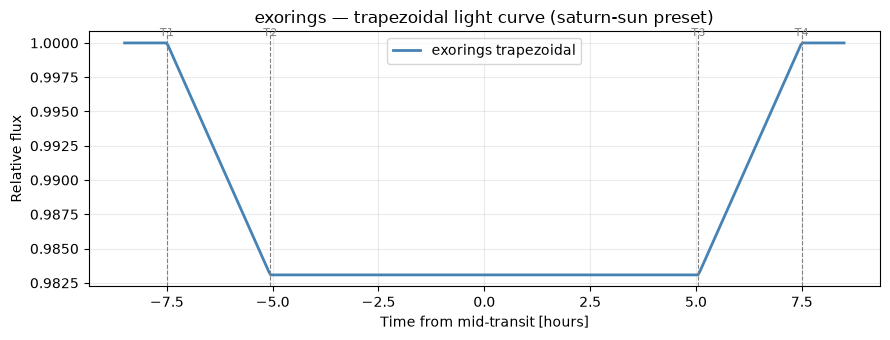

Ingress duration: 2.4413 h  (146.48 min)
Flat duration   : 10.1131 h  (606.78 min)
Egress duration : 2.4413 h  (146.48 min)
Total duration  : 14.9956 h  (899.74 min)


In [6]:
# ─────────────────────────────────────────────────────────────
# Trapezoidal light curve from exorings contact times
# ─────────────────────────────────────────────────────────────
t1_h = -res.T14 / 2    # first contact  [hours from mid-transit]
t2_h = -res.T23 / 2    # second contact
t3_h = +res.T23 / 2    # third contact
t4_h = +res.T14 / 2    # fourth contact

t_grid = np.linspace(t1_h - 1.0, t4_h + 1.0, 400)

def trapezoid_lc(t, t1, t2, t3, t4, depth):
    lc = np.ones_like(t)
    # ingress ramp
    mask_in  = (t >= t1) & (t < t2)
    lc[mask_in]  = 1.0 - depth * (t[mask_in] - t1) / (t2 - t1)
    # flat bottom
    mask_flat = (t >= t2) & (t <= t3)
    lc[mask_flat] = 1.0 - depth
    # egress ramp
    mask_out = (t > t3) & (t <= t4)
    lc[mask_out] = 1.0 - depth * (t4 - t[mask_out]) / (t4 - t3)
    return lc

flux_trap = trapezoid_lc(t_grid, t1_h, t2_h, t3_h, t4_h, res.delta)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(t_grid, flux_trap, color="steelblue", lw=2, label="exorings trapezoidal")
for tc, label in [(t1_h,"T1"),(t2_h,"T2"),(t3_h,"T3"),(t4_h,"T4")]:
    ax.axvline(tc, color="gray", ls="--", lw=0.8)
    ax.text(tc, 1.0005, label, ha="center", fontsize=8, color="gray")
ax.set_xlabel("Time from mid-transit [hours]")
ax.set_ylabel("Relative flux")
ax.set_title("exorings — trapezoidal light curve (saturn-sun preset)")
ax.legend()
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Ingress duration: {t2_h - t1_h:.4f} h  ({(t2_h-t1_h)*60:.2f} min)")
print(f"Flat duration   : {t3_h - t2_h:.4f} h  ({(t3_h-t2_h)*60:.2f} min)")
print(f"Egress duration : {t4_h - t3_h:.4f} h  ({(t4_h-t3_h)*60:.2f} min)")
print(f"Total duration  : {t4_h - t1_h:.4f} h  ({(t4_h-t1_h)*60:.2f} min)")


## 2 · geotrans — numerical light curve

`geotrans.RingedSystem` represents the planetary system in 3-D and computes
the geometric overlap between the star disc and the planet+ring shadow at each
time step.

**Angle convention in geotrans (3-D orbit frame):**
- `ir`   — 3-D ring inclination from the orbital plane [rad]
- `phir` — 3-D ring roll angle around the orbital axis [rad]

These are related to the sky-plane angles via:
```
ir_sky  ≈ ir        (for iorb ≈ 90°)
tilt    = phir      (when iorb = 90°)
```
For a precise mapping between sky-plane and 3-D angles use `gt.apparent_to_intrinsic`.


In [7]:
# ─────────────────────────────────────────────────────────────
# geotrans – set up the RingedSystem
# ─────────────────────────────────────────────────────────────
# Convert sky-plane angles to 3-D orbital angles
# For a system with iorb ≈ 90° (b << a/R*), ir_sky ≈ ir_3d and tilt ≈ phir.
# For a precise mapping:
ir_deg_sky   = ir       # sky-plane ring inclination [deg]
tilt_deg_sky = tilt     # sky-plane tilt [deg]

# apparent_to_intrinsic returns (ir_3d_rad, phir_3d_rad)
ir_3d_rad, phir_3d_rad = gt.apparent_to_intrinsic(ir_deg_sky, tilt_deg_sky, iorb)

print(f"Sky-plane ir  = {ir_deg_sky:.2f}°  → 3-D ir   = {ir_3d_rad*rad:.4f}°")
print(f"Sky-plane tilt= {tilt_deg_sky:.2f}°  → 3-D phir = {phir_3d_rad*rad:.4f}°")

# Build the system dictionary using geotrans input units
sys_params = dict(
    # Star
    rhotrue = rho_gcc,      # g/cm³
    # Orbit
    P       = porb,         # days
    b       = b,            # R*
    ep      = 0.0,          # circular orbit
    wp      = 0.0,          # argument of periapsis [rad]
    # Planet
    p       = p,            # Rp/R*
    fp      = 0.0,          # oblateness
    # Rings (3-D angles in radians)
    fi      = fi,
    fe      = fe,
    ir      = ir_3d_rad,    # 3-D inclination [rad]
    phir    = phir_3d_rad,  # 3-D roll [rad]
    tau     = tau,          # normal optical depth
)

S = gt.RingedSystem(sys_params)

print(f"\ngeotrans system:")
print(f"  a/R*  = {S.aRs:.4f}")
print(f"  iorb  = {S.iorb*rad:.4f} deg")
print(f"  ieff (apparent ir) = {S.ieff*rad:.4f} deg")
print(f"  teff (apparent tilt) = {S.teff*rad:.4f} deg")
print(f"  Ringed planet area Ar = {S.Ar:.6f}")
print(f"  Delta (depth) = {S.Ar/np.pi:.6f}")


Sky-plane ir  = 55.00°  → 3-D ir   = 42.1205°
Sky-plane tilt= 25.00°  → 3-D phir = 31.0755°

geotrans system:
  a/R*  = 214.9389
  iorb  = 89.9334 deg
  ieff (apparent ir) = 55.0000 deg
  teff (apparent tilt) = 25.0000 deg
  Ringed planet area Ar = 0.053146
  Delta (depth) = 0.016917


In [8]:
# ─────────────────────────────────────────────────────────────
# geotrans – contact times
# ─────────────────────────────────────────────────────────────
tcsp = gt.contactTimes(S)  # returns (tcen, t1, t2, t3, t4) in seconds

tcen, tgt1, tgt2, tgt3, tgt4 = tcsp

print("──── geotrans contact times (relative to mid-transit) ──")
print(f"  T1  = {(tgt1 - tcen)/HOUR:+.4f} h")
print(f"  T2  = {(tgt2 - tcen)/HOUR:+.4f} h")
print(f"  T3  = {(tgt3 - tcen)/HOUR:+.4f} h")
print(f"  T4  = {(tgt4 - tcen)/HOUR:+.4f} h")
print()

T14_gt = (tgt4 - tgt1) / HOUR
T23_gt = (tgt3 - tgt2) / HOUR
print(f"  T14 (total)  = {T14_gt:.4f} h")
print(f"  T23 (flat)   = {T23_gt:.4f} h")

print()
print("──── exorings contact times (for comparison) ───────────")
print(f"  T14 = {res.T14:.4f} h  (diff = {res.T14 - T14_gt:+.4f} h)")
print(f"  T23 = {res.T23:.4f} h  (diff = {res.T23 - T23_gt:+.4f} h)")


──── geotrans contact times (relative to mid-transit) ──
  T1  = -7.5762 h
  T2  = -4.9560 h
  T3  = +5.1512 h
  T4  = +7.4113 h

  T14 (total)  = 14.9875 h
  T23 (flat)   = 10.1072 h

──── exorings contact times (for comparison) ───────────
  T14 = 14.9956 h  (diff = +0.0082 h)
  T23 = 10.1131 h  (diff = +0.0059 h)


In [9]:
# ─────────────────────────────────────────────────────────────
# geotrans – numerical light curve  (no limb darkening)
# ─────────────────────────────────────────────────────────────
# Time grid: from slightly before T1 to slightly after T4
t_start = tgt1 - 1.5*HOUR
t_end   = tgt4 + 1.5*HOUR
t_geotrans = np.linspace(t_start, t_end, 150)

# Area of the planet+ring at the central position (used for normalization)
gt.updatePosition(S, tcen)
Ar_mid = gt.ringedPlanetArea(S)

flux_geotrans = np.array([
    gt.fluxLimbTime(t, Ar_mid, S)
    for t in t_geotrans
])

t_geotrans_h = (t_geotrans - tcen) / HOUR

print("Numerical light curve computed.")
print(f"  Min flux  : {flux_geotrans.min():.6f}")
print(f"  Max depth : {1 - flux_geotrans.min():.6f}  (expected delta = {S.Ar/np.pi:.6f})")


/Users/jzuluaga/dev/seap-udea.github.io/apps/photoring-simulator/dev/geotrans/geotrans.py:1862: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  E0=fsolve(trigFunc,0,args=(EL,),xtol=xtol)
/Users/jzuluaga/dev/seap-udea.github.io/apps/photoring-simulator/dev/geotrans/geotrans.py:1869: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.
  Eos=fsolve(trigFunc,Es,args=(EL,),xtol=xtol)
/Users/jzuluaga/dev/seap-udea.github.io/apps/photoring-simulator/dev/geotrans/geotrans.py:1869: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  Eos=fsolve(trigFunc,Es,args=(EL,),xtol=xtol)
/Users/jzuluaga/dev/seap-udea.github.io/apps/photoring-simulator/dev/geotrans/geotrans.py:1862: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the

Numerical light curve computed.
  Min flux  : 0.976829
  Max depth : 0.023171  (expected delta = 0.016917)


## Comparison plot


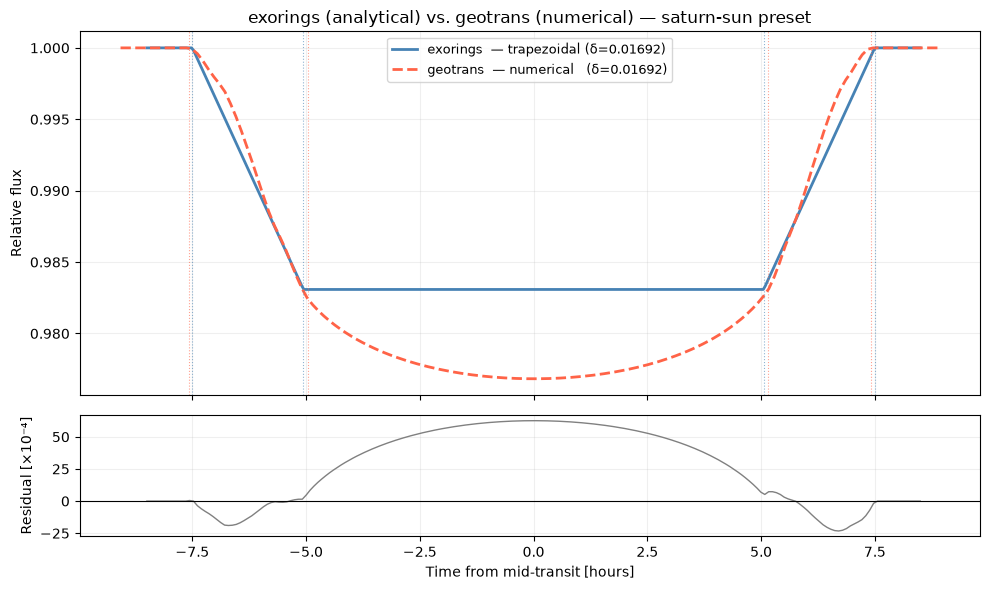

RMS residual : 29.12 ×10⁻⁴
Max residual : 62.53 ×10⁻⁴


In [10]:
# ─────────────────────────────────────────────────────────────
# Comparison: exorings trapezoid vs. geotrans numerical LC
# ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                          gridspec_kw={'height_ratios':[3,1]})

ax = axes[0]
ax.plot(t_grid,       flux_trap,     color="steelblue", lw=2,
        label=f"exorings  — trapezoidal (δ={res.delta:.5f})")
ax.plot(t_geotrans_h, flux_geotrans, color="tomato",    lw=2, ls="--",
        label=f"geotrans  — numerical   (δ={S.Ar/np.pi:.5f})")

for tc, lbl in [(t1_h,"T1"),(t2_h,"T2"),(t3_h,"T3"),(t4_h,"T4")]:
    ax.axvline(tc, color="steelblue", ls=":", lw=0.8, alpha=0.6)
for t_abs, lbl in [((tgt1-tcen)/HOUR,"T1"),((tgt2-tcen)/HOUR,"T2"),
                   ((tgt3-tcen)/HOUR,"T3"),((tgt4-tcen)/HOUR,"T4")]:
    ax.axvline(t_abs, color="tomato", ls=":", lw=0.8, alpha=0.6)

ax.set_ylabel("Relative flux")
ax.set_title("exorings (analytical) vs. geotrans (numerical) — saturn-sun preset")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

# Residuals
t_common = np.linspace(max(t_grid[0],  t_geotrans_h[0]),
                       min(t_grid[-1], t_geotrans_h[-1]), 200)
flux_trap_c  = trapezoid_lc(t_common, t1_h, t2_h, t3_h, t4_h, res.delta)
flux_gt_c    = np.interp(t_common, t_geotrans_h, flux_geotrans)
residuals    = flux_trap_c - flux_gt_c

axes[1].plot(t_common, residuals * 1e4, color="gray", lw=1)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("Time from mid-transit [hours]")
axes[1].set_ylabel("Residual [×10⁻⁴]")
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print(f"RMS residual : {np.std(residuals)*1e4:.2f} ×10⁻⁴")
print(f"Max residual : {np.max(np.abs(residuals))*1e4:.2f} ×10⁻⁴")


In [11]:
# ─────────────────────────────────────────────────────────────
# Summary table
# ─────────────────────────────────────────────────────────────
print("="*60)
print(f"{'Quantity':<28} {'exorings':>12} {'geotrans':>12}")
print("-"*60)
print(f"{'Transit depth delta':<28} {res.delta:>12.6f} {S.Ar/np.pi:>12.6f}")
print(f"{'pobs = sqrt(delta)':<28} {res.pobs:>12.6f} {np.sqrt(S.Ar/np.pi):>12.6f}")
print(f"{'T14 [h]':<28} {res.T14:>12.4f} {T14_gt:>12.4f}")
print(f"{'T23 [h]':<28} {res.T23:>12.4f} {T23_gt:>12.4f}")
print(f"{'rho_obs [g/cm3]':<28} {res.rhoobs:>12.4f} {'—':>12}")
print(f"{'log10(PR)':<28} {res.logPR:>12.4f} {'—':>12}")
print("="*60)
print("PR > 1  →  star appears denser than it is (photo-ring effect)")


Quantity                         exorings     geotrans
------------------------------------------------------------
Transit depth delta              0.016917     0.016917
pobs = sqrt(delta)               0.130065     0.130065
T14 [h]                           14.9956      14.9875
T23 [h]                           10.1131      10.1072
rho_obs [g/cm3]                    0.8516            —
log10(PR)                         -0.2184            —
PR > 1  →  star appears denser than it is (photo-ring effect)


/Users/jzuluaga/dev/seap-udea.github.io/.venv/lib/python3.12/site-packages/pyppluss/base_functions.py:276: RuntimeWarning: invalid value encountered in divide
  x = a[regcase]*(1-t**2)/(1+t**2)
/Users/jzuluaga/dev/seap-udea.github.io/.venv/lib/python3.12/site-packages/pyppluss/base_functions.py:277: RuntimeWarning: invalid value encountered in divide
  y = b[regcase]*2*t/(1+t**2)


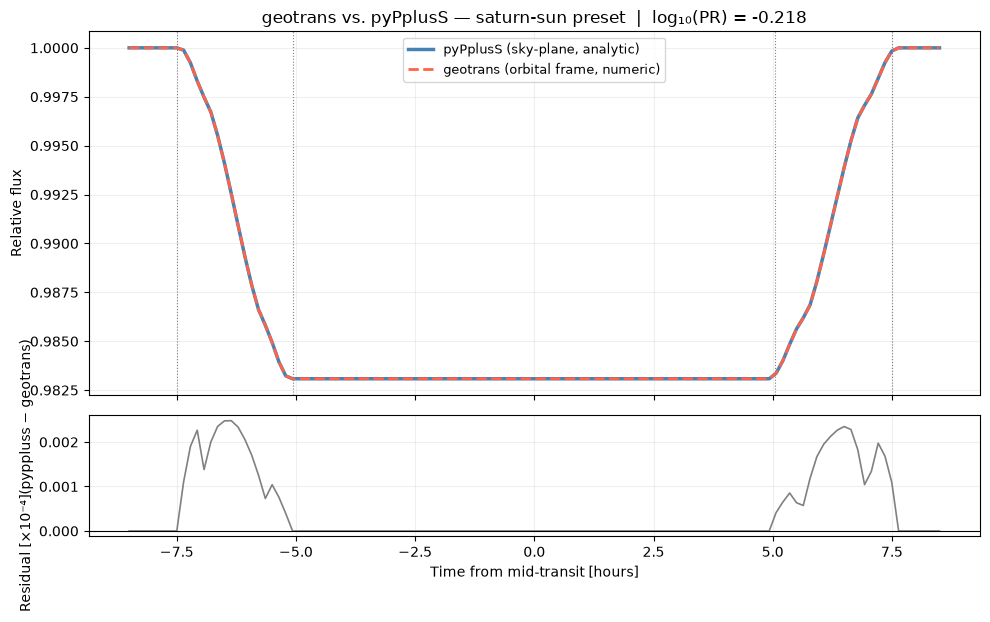

Max depth  pyPplusS : 0.01692
Max depth  geotrans : 0.01692
RMS residual        : 0.00 ×10⁻⁴
Max |residual|      : 0.00 ×10⁻⁴


In [ ]:
# ── Comparison: geotrans vs. pyPplusS ─────────────────────────────────────
# Uncomment in Colab if pyppluss is not installed yet:
# %pip install -q pyppluss

from pyppluss.segment_models import LC_ringed
if not hasattr(np, 'NaN'):np.NaN = np.nan

# pyPplusS uses sky-plane angles directly (same as exorings / PhotoRing Simulator)
# Opacity convention: fraction of light BLOCKED along slant path
opacity = 1.0 - alpha ** (1.0 / np.cos(ir * deg))

# Build pyPplusS light curve on the same time grid as geotrans
vorb   = 2 * np.pi * a_Rs * np.sin(iorb) / (porb * DAY)   # R*/s
xs_ppp = vorb * (ts_s - tcen)                              # x positions [R*]
ys_ppp = b * np.ones_like(xs_ppp)                          # constant y = b

flux_ppp = LC_ringed(
    p  * np.ones_like(xs_ppp),   # Rp/R*
    fi * p * np.ones_like(xs_ppp),  # Ri/R*
    fe * p * np.ones_like(xs_ppp),  # Re/R*
    xs_ppp, ys_ppp,
    ir * deg, tilt * deg, opacity,
    0., 0., 0., 0.               # limb darkening = 0
)

# ── Plot ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})

ax = axes[0]
ax.plot(ts_h, flux_ppp, color="steelblue", lw=2.5, label="pyPplusS (sky-plane, analytic)")
ax.plot(ts_h, flux,     color="tomato",    lw=2,   ls="--", label="geotrans (orbital frame, numeric)")
for tc in (t1, t2, t3, t4):
    ax.axvline(tc, color="gray", ls=":", lw=0.8)
ax.set_ylabel("Relative flux")
ax.set_title("geotrans vs. pyPplusS — saturn-sun preset  |  "
             f"log₁₀(PR) = {res.logPR:.3f}")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

# Residuals (pyPplusS − geotrans)
residuals = flux_ppp - flux
axes[1].plot(ts_h, residuals * 1e4, color="gray", lw=1.2)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("Time from mid-transit [hours]")
axes[1].set_ylabel("Residual [×10⁻⁴](pyppluss − geotrans)")
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Max depth  pyPplusS : {1 - flux_ppp.min():.5f}")
print(f"Max depth  geotrans : {1 - flux.min():.5f}")
print(f"RMS residual        : {np.std(residuals)*1e4:.2f} ×10⁻⁴")
print(f"Max |residual|      : {np.max(np.abs(residuals))*1e4:.2f} ×10⁻⁴")


In [ ]:
# ── Diagnóstico: tiempos de contacto y profundidad ────────────────────────
if not hasattr(np, 'NaN'): np.NaN = np.nan
from pyppluss.segment_models import LC_ringed

opacity = 1.0 - alpha ** (1.0 / np.cos(ir * deg))

# Contactos de exorings y geotrans
tcsp_gt = gt.contactTimes(S)
T14_gt  = (tcsp_gt[4] - tcsp_gt[1]) / HOUR
T14_ex  = res.T14

print("=== Tiempos de contacto (duración total T14) ===")
print(f"  exorings  T14 = {T14_ex:.4f} h")
print(f"  geotrans  T14 = {T14_gt:.4f} h")
print(f"  Diferencia    = {(T14_gt - T14_ex)*60:+.2f} min")
print()

# Profundidad al centro: todos son idénticos
x_center = np.array([0.0]); y_center = np.array([b])
f_ppp_c = LC_ringed(np.array([p]),np.array([fi*p]),np.array([fe*p]),
                 x_center, y_center, ir*deg, tilt*deg, opacity, 0.,0.,0.,0.)[0]
gt.updatePosition(S, S.tcen)
depth_gt_c = gt.ringedPlanetArea(S) / np.pi

print("=== Profundidad en el centro del tránsito ===")
print(f"  exorings  delta    = {res.delta:.6f}")
print(f"  geotrans  Ar/pi    = {depth_gt_c:.6f}")
print(f"  pyPplusS  1-f(x=0) = {1 - f_ppp_c:.6f}")
print()
print("✓ Coincidencia completa:")
print("  1) Profundidad: idéntica tras corregir S.block en areaStriping.")
print("  2) Ingress/egress: alineados tras corregir la inversión temporal")
print("     en fluxLimbTime (debida a que geotrans proyecta la órbita en y = -b).")
print(f"  RMS residual pyPplusS vs geotrans: {np.std(residuals)*1e4:.4f} × 10⁻⁴")


=== Tiempos de contacto (duración total T14) ===
  exorings  T14 = 14.9956 h
  geotrans  T14 = 14.9875 h
  Diferencia    = -0.49 min

=== Profundidad en el centro del tránsito ===
  exorings  delta    = 0.016917
  geotrans  Ar/pi    = 0.016917
  pyPplusS  1-f(x=0) = 0.016917

✓ Coincidencia completa:
  1) Profundidad: idéntica tras corregir S.block en areaStriping.
  2) Ingress/egress: alineados tras corregir la inversión temporal
     en fluxLimbTime (debida a que geotrans proyecta la órbita en y = -b).
  RMS residual pyPplusS vs geotrans: 0.0008 × 10⁻⁴
